# **Problem Set 7**
## CHEM 5541 - Chemical Dynamics
### *Samuel Arnold*
### *10/23/26*
***

## 1.) Hamiltonian Equations

### 1a) 

$$H = \frac{p_{COM}^2}{2M} \frac{p_{rel}^2}{2\mu} + V(x_{rel})$$

The Hamilton equations can be shown as:

$$\frac{dx}{dt} = \frac{\partial H}{\partial p}$$

$$\frac{dp}{dt} = - \frac{\partial H}{\partial x}$$

For the COM frame we have:

$$\frac{dx_{COM}}{dt} = \frac{p_{COM}}{M}$$

$$\frac{dp_{COM}}{dt} =  0 - \frac{\partial V(x_{COM})}{\partial x_{COM}} = 0$$

As it is stated that the potential function is only dependent on $x_{rel}$. So finding the relative terms:

$$\frac{dx_{rel}}{dt} = \frac{p_{rel}}{\mu}$$

$$\frac{dp_{rel}}{dt} =  0 - \frac{\partial V(x_{rel})}{\partial x_{rel}} = - \frac{\partial V(x_{rel})}{\partial x_{rel}} $$

These DEs make sense as for the COM frame, the change in momentum is zero as the total momentum of the COM is conserved and results in the COM moving at a constant velocity. Which in itself is confirmed by the first equation as the velocity is equal to $\frac{p_{COM}}{M}$, with $p_{COM}$ being stated previously as being constant. For the relative frame, the velocity is related to the momentum divided by the reduced mass, $\mu$, instead of the total mass, $M$. While the change of momentum is proportional to the change in the potential as it is dependent on $x_{rel}$.

### 1b.)

For an inverted harmonic oscillator, the potential can be represented by:

$$V = -\frac{1}{2} K x^2$$

which can be substituted into the Hamiltonian:

$$H = \frac{p^2}{2m} - \frac{1}{2} K x^2$$

Where we can now use the Hamilton equations:

$$\frac{dx}{dt} = \frac{\partial H}{\partial p} = \frac{p}{m}$$

$$\frac{d^2x}{dt^2} = \frac{1}{m} \frac{dp}{dt}$$

$$\frac{dp}{dt} = - \frac{\partial H}{\partial x} =  K x$$

Combining the previous two equations together we get:

$$\frac{d^2x}{dt^2} = \frac{K}{m} x$$

or 

$$\ddot x - \frac{K}{m} x = 0$$

### 1c.)

$$x(t) = A e^{-i \omega t}$$

Treating this like solving for the frequency of the harmonic oscillator system (which is real), but with the inverted harmonic oscillator that should result in an imaginary freqeuncy.

So first:

$$\dot x(t) = (-i \omega) A e^{-i \omega t}$$
$$\ddot x(t) = - \omega^2 A e^{-i \omega t}$$

Which are substituted into:

$$\ddot x - \frac{K}{m} x = 0$$

to get:

$$- \omega^2 A e^{-i \omega t} - \frac{K}{m} A e^{-i \omega t} = 0$$

$$- \omega^2  - \frac{K}{m} = 0$$

$$\omega = \sqrt{- \frac{K}{m}}$$

thus resulting in:

$$\omega = \pm i \sqrt{\frac{K}{m}}$$

which is imaginary.

Substituting $\omega = i \Omega$ into $x(t)$

$$x(t) = A e^{-i (i \Omega) t}$$

$$x(t) = A e^{\Omega t}$$

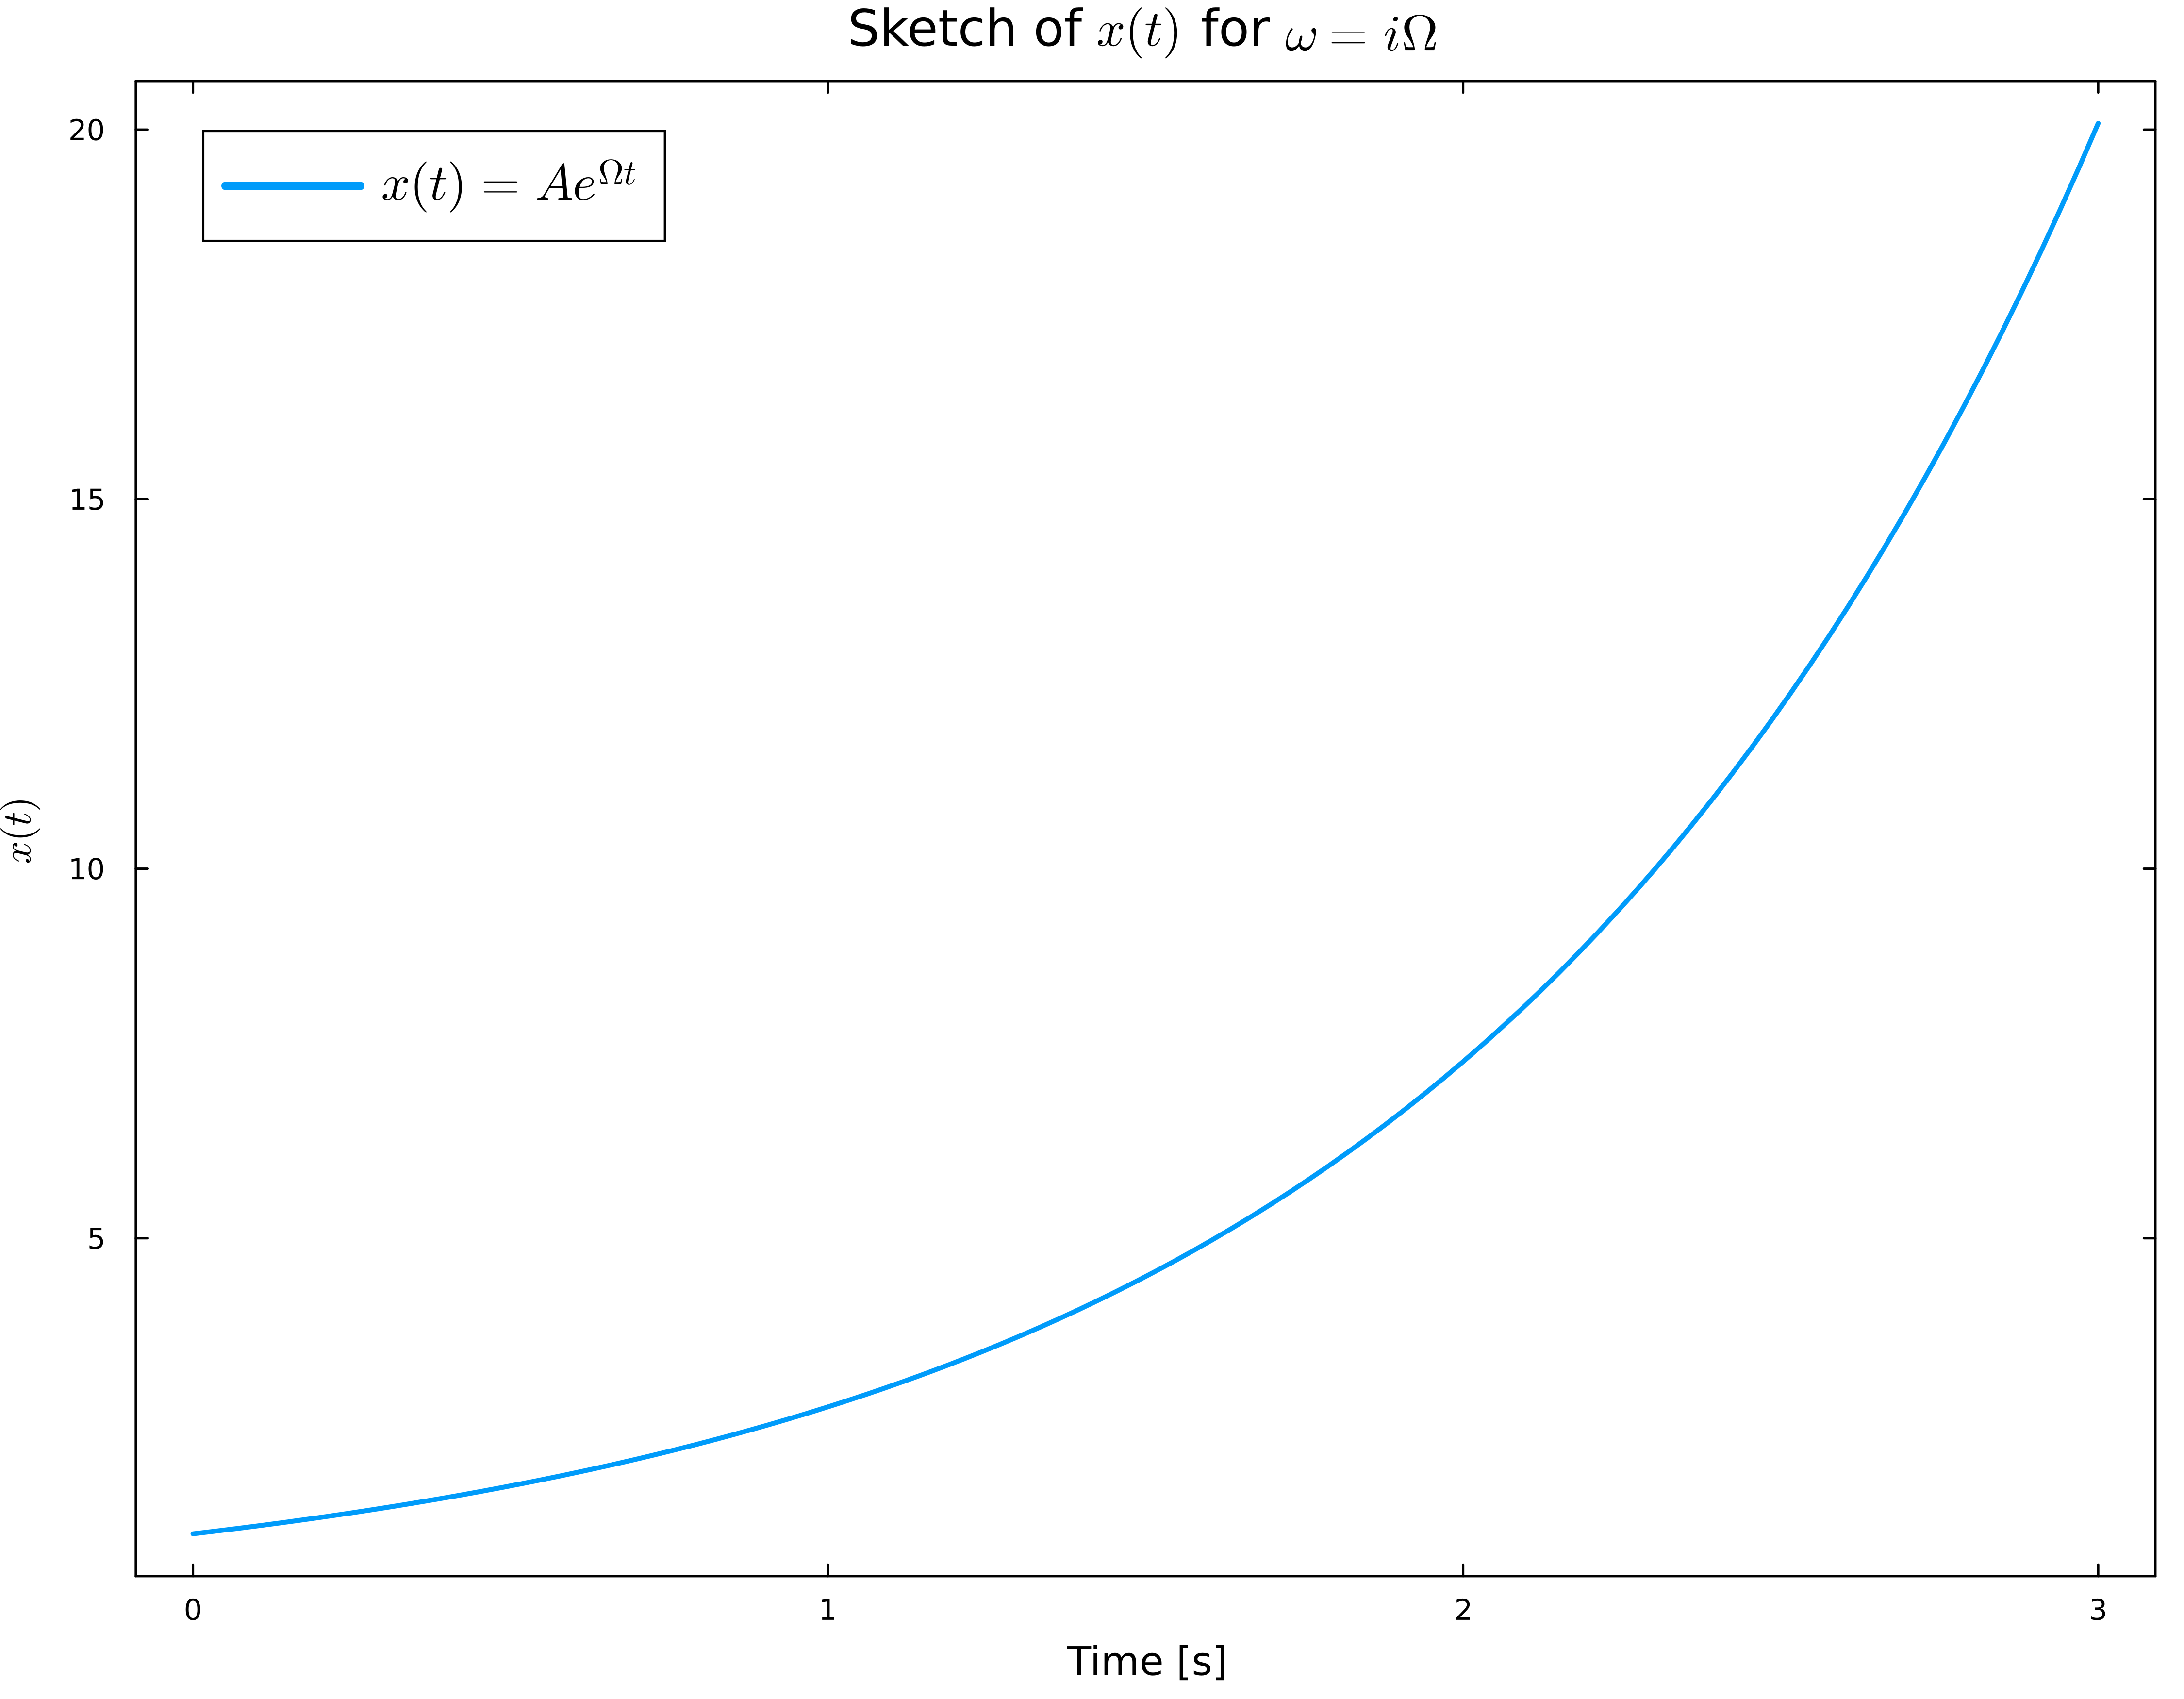

In [13]:
using Plots

gr()

A = 1
Ω = 1
t_range = range(0,3, length=100)

x_t = A .* exp.(Ω .* t_range)

plot(
    t_range,
    x_t,
    title = raw"Sketch of $x(t)$ for $\omega = i \Omega$",
    xlabel = "Time [s]",
    ylabel = raw"$x(t)$",
    label = raw"$x(t) = A e^{\Omega t}$",
    framestyle=:box,
    grid=false,
    linewidth=2.0,
    legendfontsize = 14,
    size = (900, 700),
    dpi = 500,
)

***
## 2.) Partition Functions

### 2a.)

$$z_{vib}^{HO} = \frac{1}{1-e^{- \frac{\hbar \omega}{k_B T}}}$$

$$z_{vib}^{SC} = \frac{k_B T}{\hbar \omega_0}$$

With $\omega_{HD} = 3813$ cm $^{-1}$

In [10]:
h = 6.626e-34
k_B = 1.380649e-23
c = 2.99792e8 
ω = 3813 * 100 # m^-1


T = [100, 300, 1000, 3000]

z_ho = 1 ./ (1 .- exp.((-h .* ω * c) ./ (k_B .* T)))
z_sc = (k_B .* T) ./ (h .* ω * c)

println("z_ho = : ", round.(z_ho, digits=5))
println("z_sc = : ", round.(z_sc, digits=5))

z_ho = : [1.0, 1.0, 1.00416, 1.19137]
z_vib = : [0.01823, 0.05468, 0.18228, 0.54685]


The error drops to 10% at T = 25570.37 K


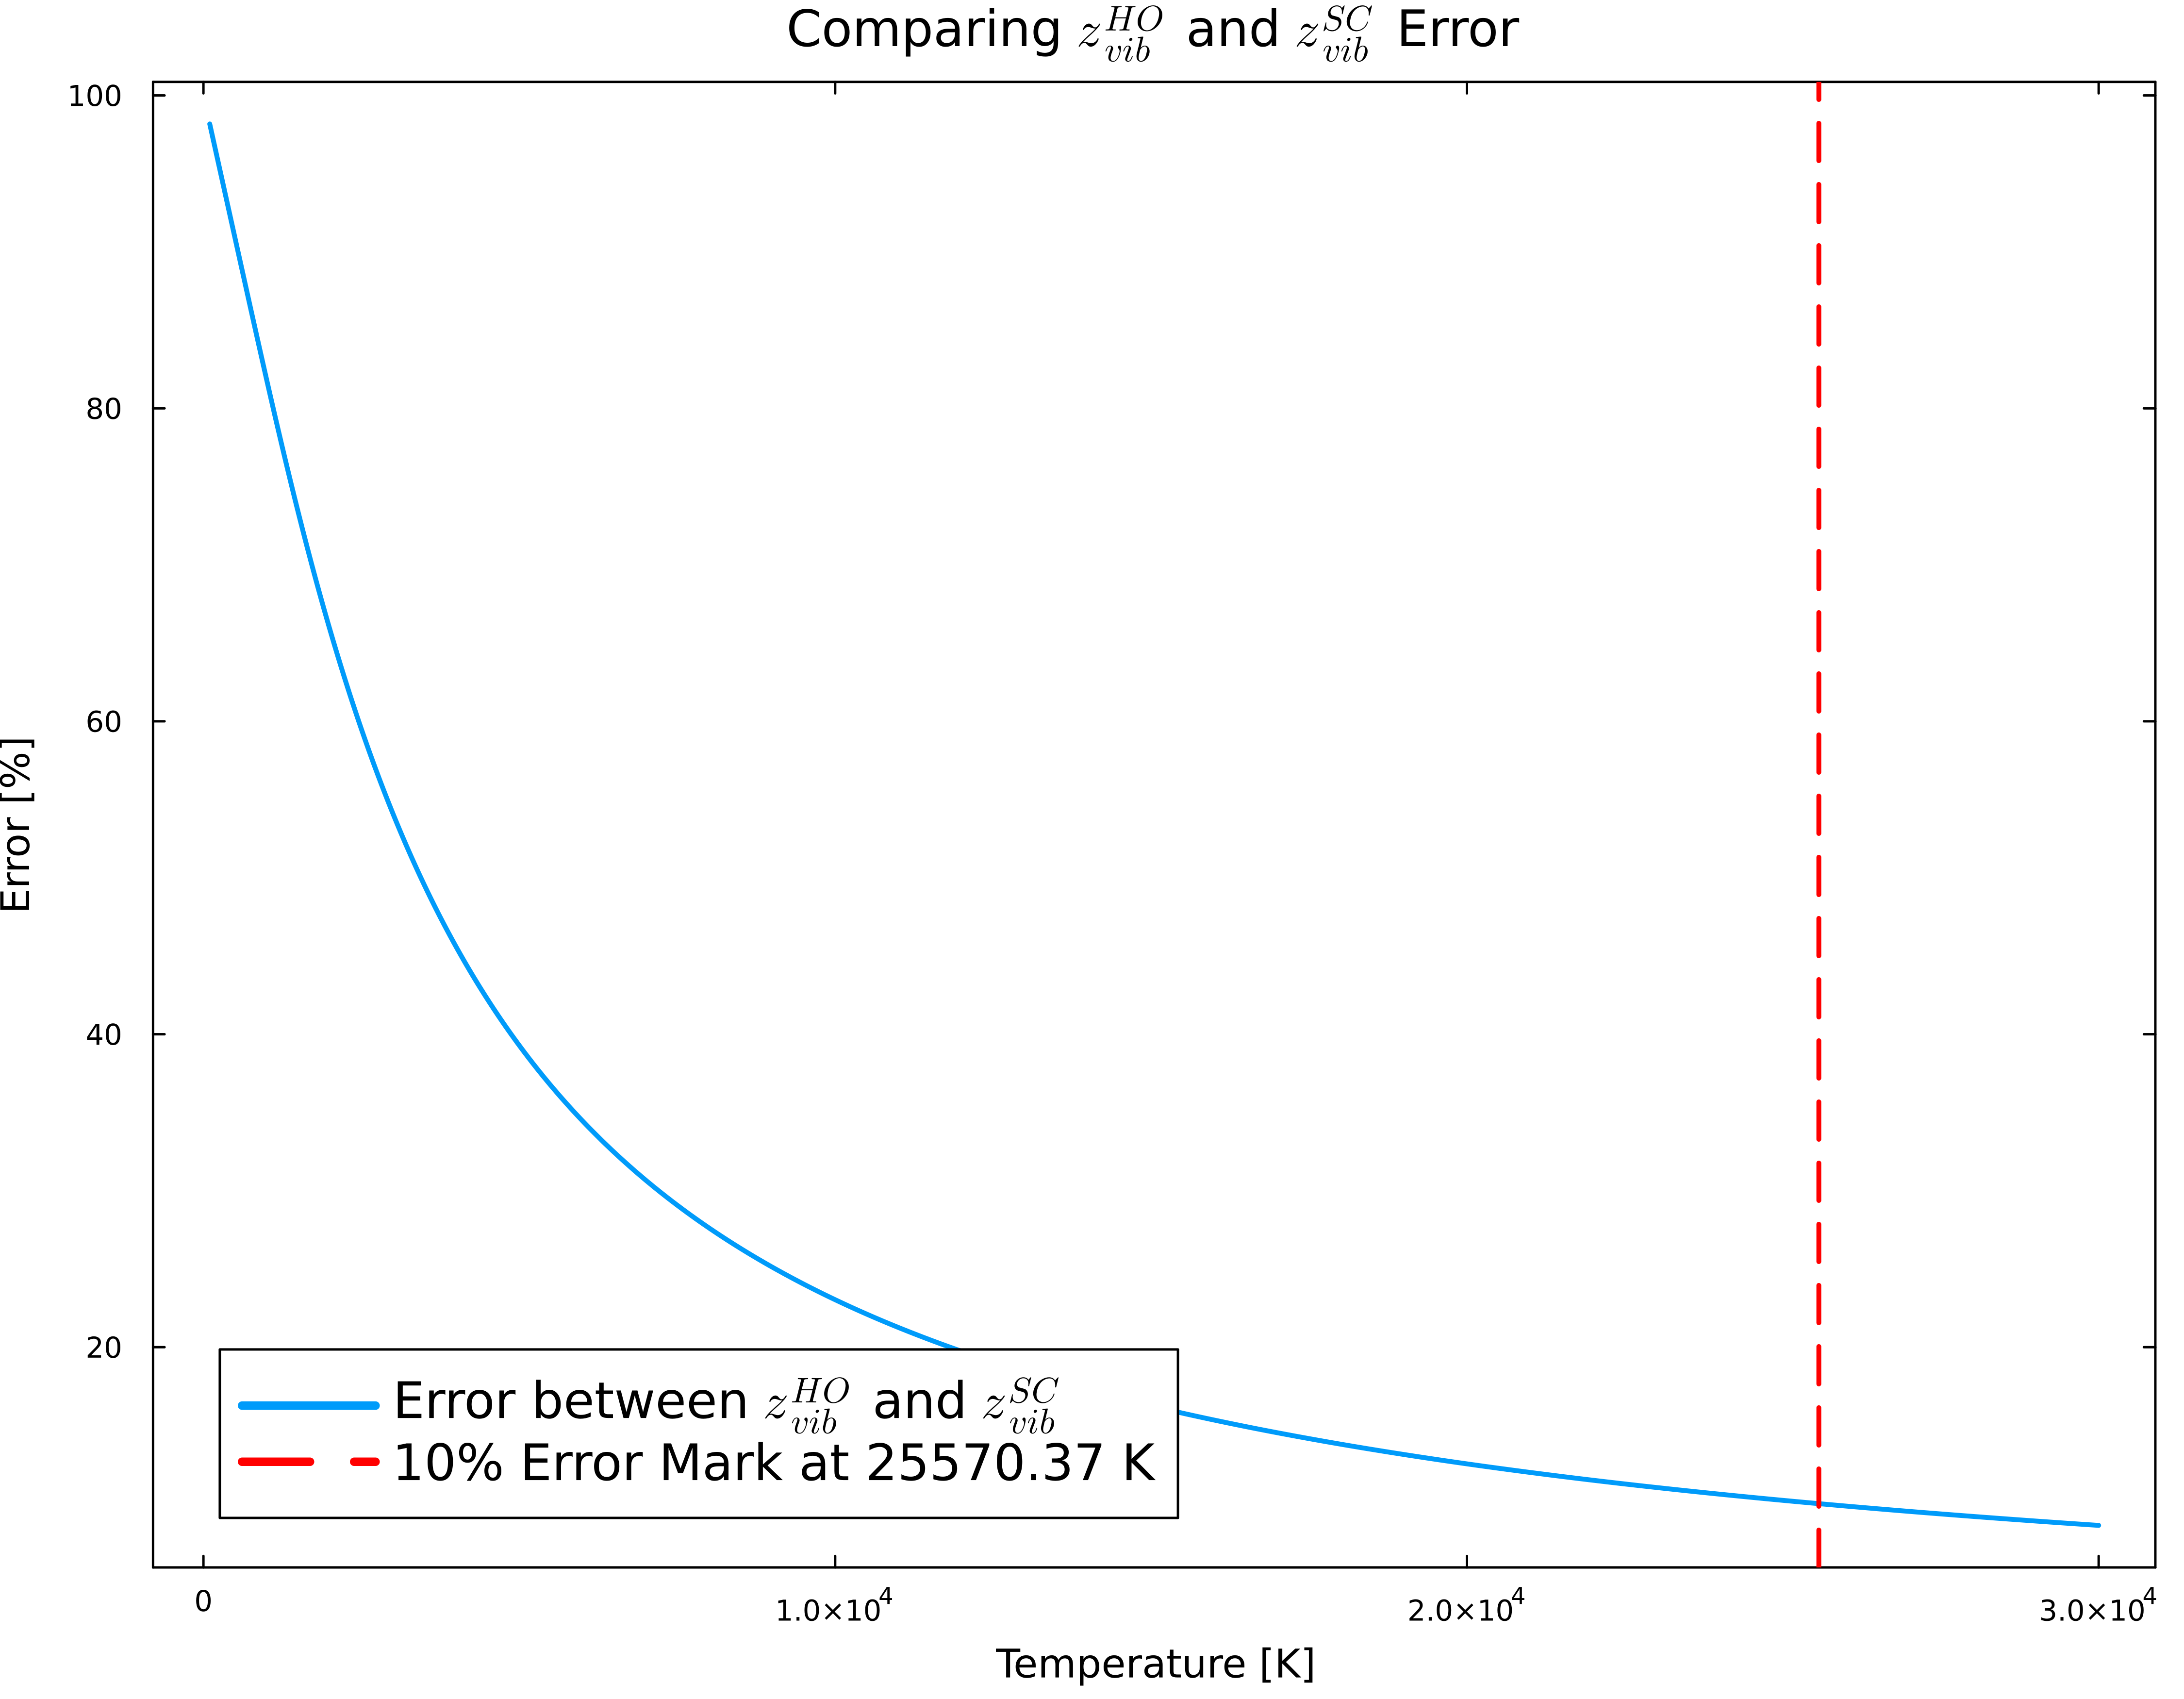

In [51]:
T_range = range(100, 30000, length=1000)
z_ho = 1 ./ (1 .- exp.((-h .* ω * c) ./ (k_B .* T_range)))
z_sc = (k_B .* T_range) ./ (h .* ω * c)

error = (z_ho .- z_sc) ./ (z_ho) * 100

error_10 = 10

closest_idx = argmin(abs.(error .- error_10))
T_intersect = T_range[closest_idx]

println("The error drops to 10% at T = $(round(T_intersect, digits=2)) K")

plot(
    T_range,
    error,
    title = raw"Comparing $z_{vib}^{HO}$ and $z_{vib}^{SC}$ Error",
    xlabel = "Temperature [K]",
    ylabel = "Error [%]",
    label = raw"Error between $z_{vib}^{HO}$ and $z_{vib}^{SC}$",
    framestyle=:box,
    grid=false,
    linewidth=2.0,
    legendfontsize = 14,
    size = (900, 700),
    dpi = 500,
)

vline!(
    [T_intersect],
    label = "10% Error Mark at $(round(T_intersect, digits=2)) K" ,
    linewidth=2.0,
    color=:red,
    linestyle = :dash
)

### 2b.)

$$z_{rot}^{RR} = \sum_{J=0}^{\infty} (2J+1) e^{-BJ(J+1) / k_B T}$$

$$z_{rot}^{SC} = \frac{k_B T}{B}$$

In [61]:
h = 6.626e-34
k_B = 1.380649e-23
c = 2.99792e8 
B = 45.6 * 100      # m^-1

T = [100, 300, 1000, 3000]

z_rot_rr = sum((2*J+1) .* exp.((-h * c *B*J*(J+1)) ./ (k_B .* T)) for J in 0:100)
z_rot_sc = (k_B .* T) ./ (h * c * B)

println("z_rot_rr = : ", round.(z_rot_rr, digits=5))
println("z_rot_sc = : ", round.(z_rot_sc, digits=5))

z_rot_rr = : [1.90799, 4.92121, 15.57994, 46.06133]
z_rot_sc = : [1.52422, 4.57265, 15.24218, 45.72653]


The error drops to 10% at T = 210.11 K


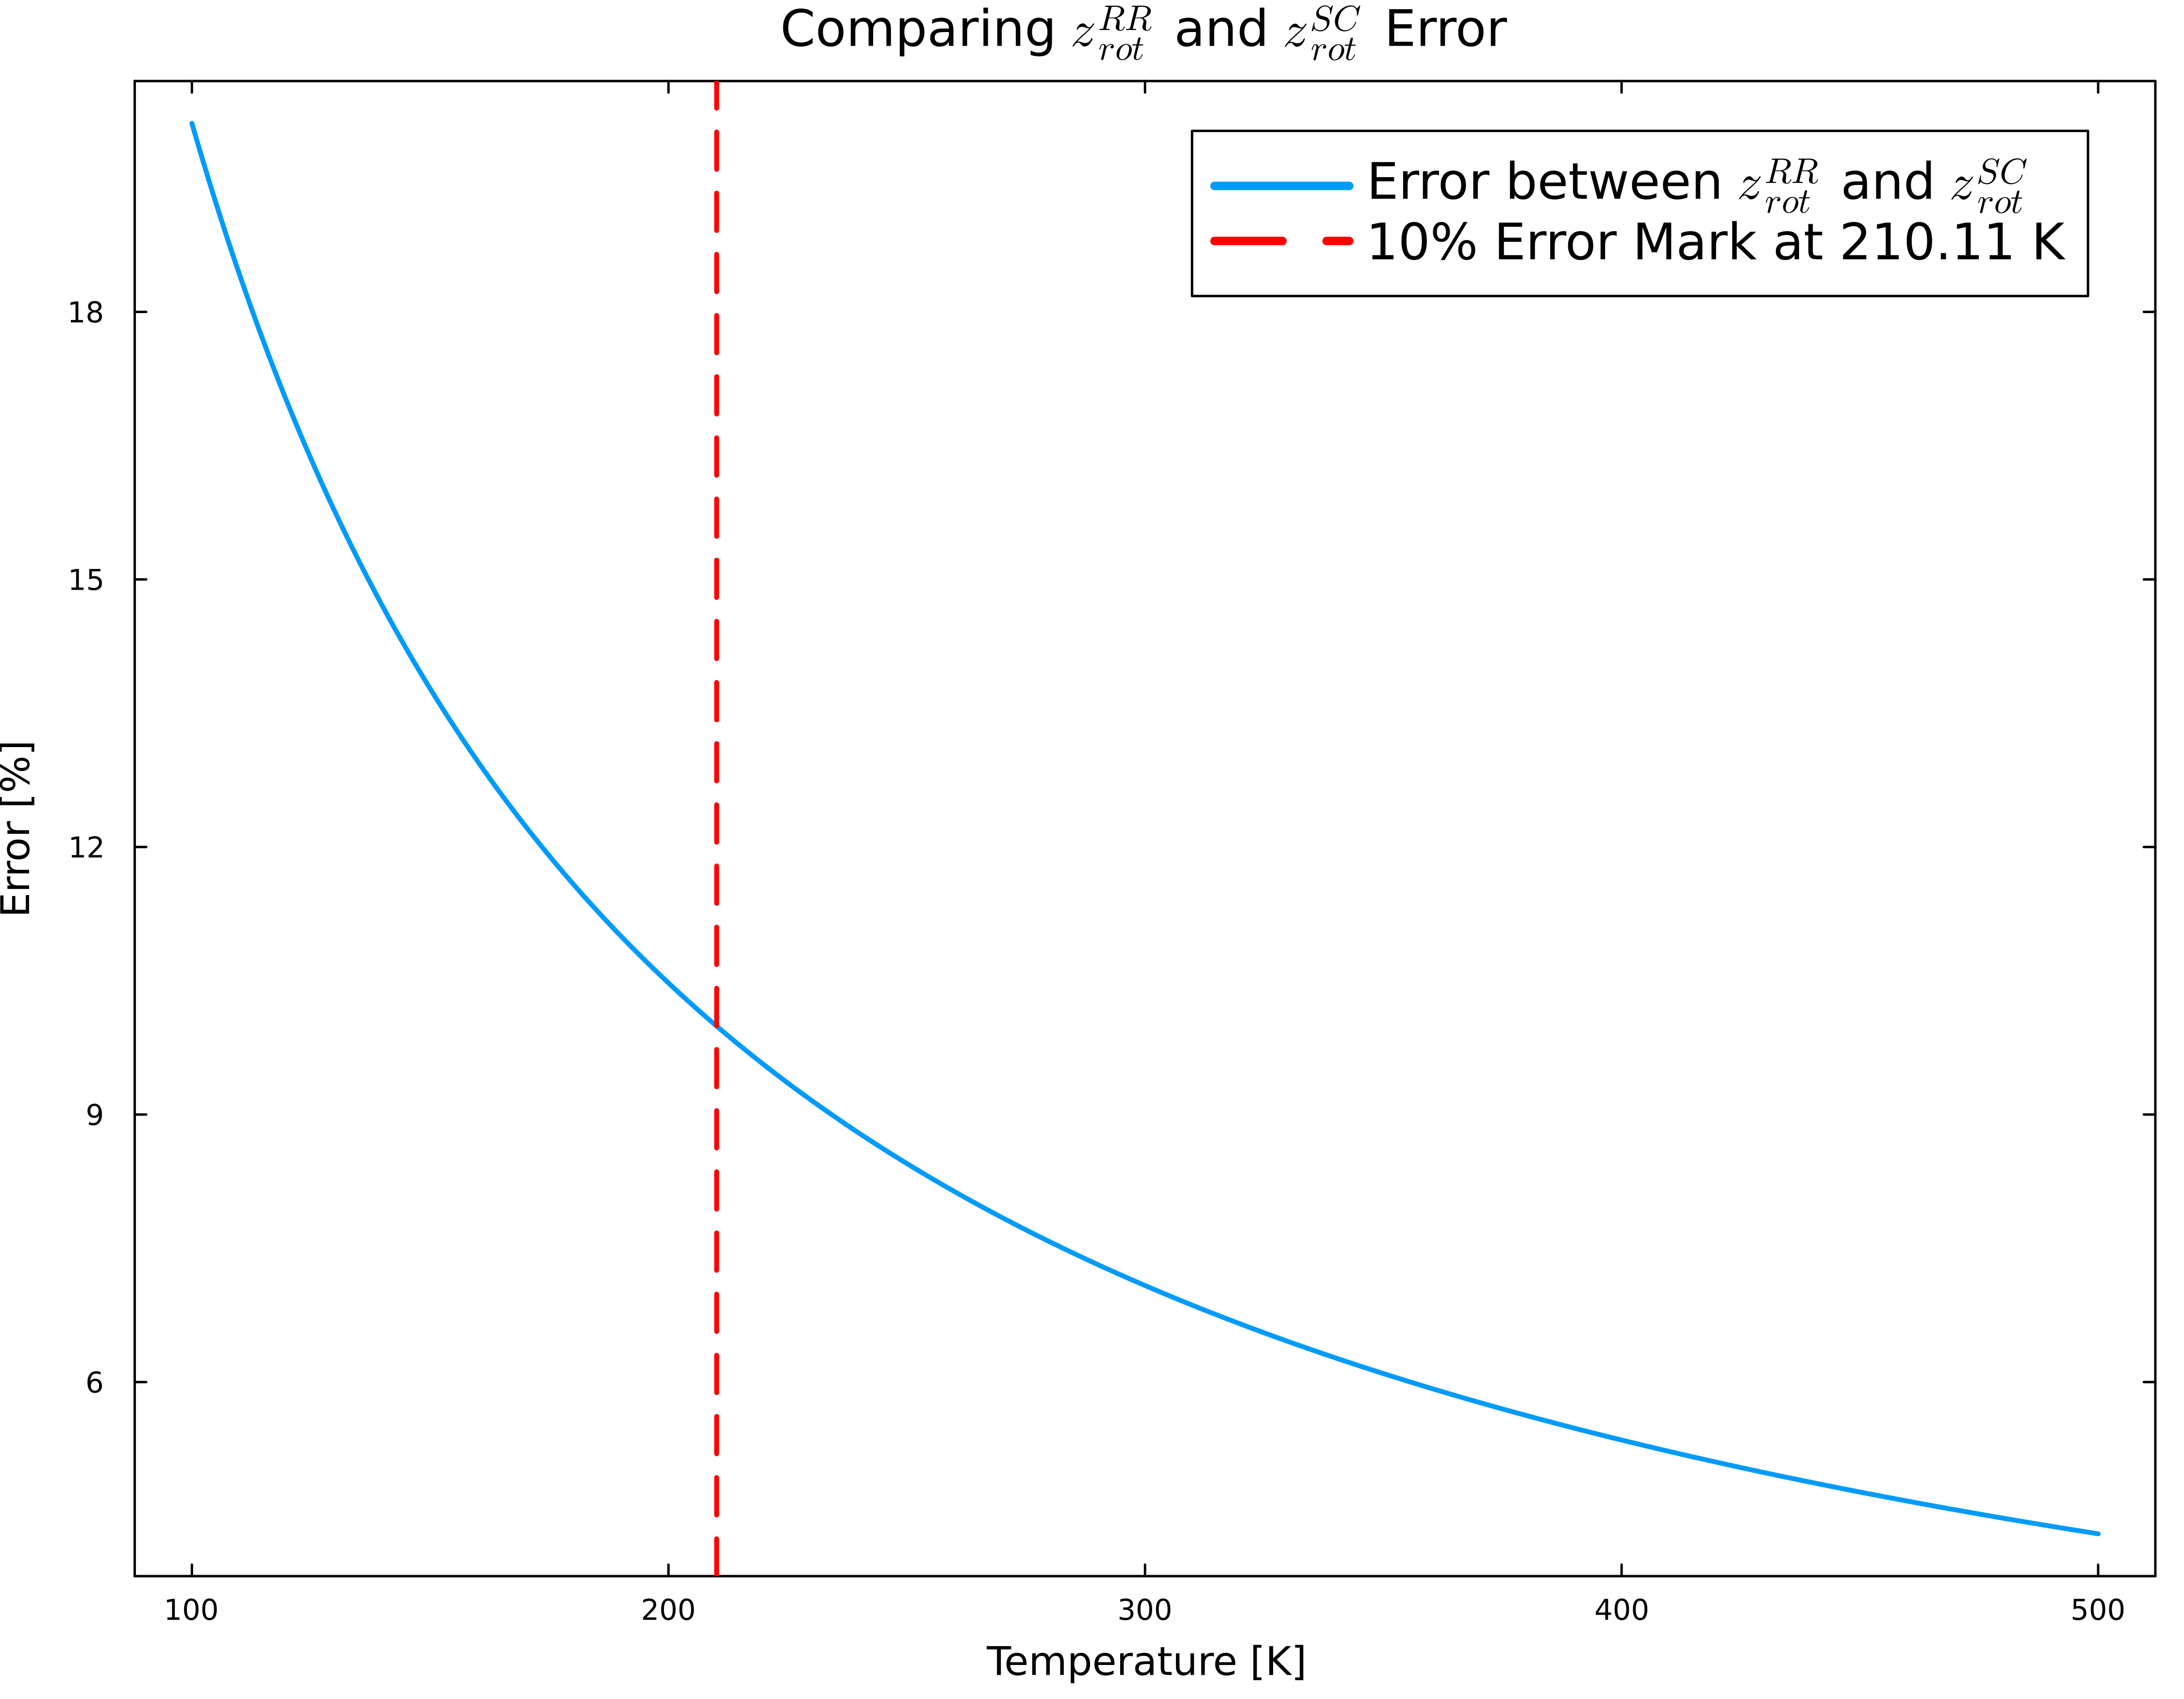

In [62]:
T_range = range(100, 500, length=1000)
z_rot_rr = sum((2*J+1) .* exp.((-h * c *B*J*(J+1)) ./ (k_B .* T_range)) for J in 0:1000)
z_rot_sc = (k_B .* T_range) ./ (h * c * B)

error = (z_rot_rr .- z_rot_sc) ./ (z_rot_rr) * 100

error_10 = 10

closest_idx = argmin(abs.(error .- error_10))
T_intersect = T_range[closest_idx]

println("The error drops to 10% at T = $(round(T_intersect, digits=2)) K")

plot(
    T_range,
    error,
    title = raw"Comparing $z_{rot}^{RR}$ and $z_{rot}^{SC}$ Error",
    xlabel = "Temperature [K]",
    ylabel = "Error [%]",
    label = raw"Error between $z_{rot}^{RR}$ and $z_{rot}^{SC}$",
    framestyle=:box,
    grid=false,
    linewidth=2.0,
    legendfontsize = 14,
    size = (900, 700),
    dpi = 500,
)

vline!(
    [T_intersect],
    label = "10% Error Mark at $(round(T_intersect, digits=2)) K" ,
    linewidth=2.0,
    color=:red,
    linestyle = :dash
)

### 2c.) 

$$\theta_{vib} = \frac{\hbar \omega_0}{k_B}$$

$$\theta_{rot} = \frac{B}{k_B}$$

In [63]:
h = 6.626e-34
k_B = 1.380649e-23
c = 2.99792e8 
ω = 75 * 100 # m^-1
B = 0.132 * 100      # m^-1

T = 300

z_rot_rr = sum((2*J+1) .* exp.((-h * c *B*J*(J+1)) ./ (k_B .* T)) for J in 0:1000)
z_rot_sc = (k_B .* T) ./ (h * c * B)

z_vib_ho = 1 ./ (1 .- exp.((-h .* ω * c) ./ (k_B .* T)))
z_vib_sc = (k_B .* T) ./ (h .* ω * c)

println("z_vib_ho = : ", round.(z_vib_ho, digits=5))
println("z_vib_sc = : ", round.(z_vib_sc, digits=5))

println("z_rot_rr = : ", round.(z_rot_rr, digits=5))
println("z_rot_sc = : ", round.(z_rot_sc, digits=5))

θ_vib = h * c * ω / k_B
θ_rot = h * c * B / k_B

println("θ_vib = : ", round.(θ_vib, digits=5), " K")
println("θ_rot = : ", round.(θ_rot, digits=5), " K")


z_vib_ho = : 3.31008
z_vib_sc = : 2.78017
z_rot_rr = : 1579.97706
z_rot_sc = : 1579.64368
θ_vib = : 107.90696 K
θ_rot = : 0.18992 K


The difference between the harmonic approximation and the semiclassical result for the vibrational partition function was small at 300 K, but not as small as the rigid rotor and the semiclassical result because the characteristic vibrational temperature is much closer to 300 K than the rotational.

***
## 3.) Vibrational Partition Function for the Morse Oscillator

### 3a.) 

$$E_v = \hbar \omega_0 \left(v + \frac{1}{2} \right) - \frac{\hbar^2 \omega_0^2}{4D} \left(v + \frac{1}{2} \right)^2$$

$$E_0 = \hbar \omega_0 \left(\frac{1}{2}\right) - \frac{\hbar^2 \omega_0^2}{4D} \left(\frac{1}{2} \right)^2$$
$$= \frac{\hbar \omega_0}{2} - \frac{\hbar^2 \omega_0^2}{16D}$$

$$\epsilon_v = E_v - E_0$$

$$= \left[\hbar \omega_0 \left(v + \frac{1}{2} \right) - \frac{\hbar^2 \omega_0^2}{4D} \left(v + \frac{1}{2} \right)^2 \right] - \left[\frac{\hbar \omega_0}{2} - \frac{\hbar^2 \omega_0^2}{16D} \right]$$

$$= \hbar \omega_0 \left[\left(v + \frac{1}{2} \right) -  \frac{1}{2}\right] - \frac{\hbar^2 \omega_0^2}{4D} \left[\left(v + \frac{1}{2} \right)^2 - \frac{1}{16} \right]$$

$$\epsilon_v = \hbar \omega_0 v - \frac{\hbar^2 \omega_0^2}{4D} v(v+1)$$

$$z_{vib}^{MO} = \sum_{v=0}^N e^{-\epsilon_v / k_B T}$$

$$z_{vib}^{MO} = \sum_{v=0}^N e^{-\left[\hbar \omega_0 v - \frac{\hbar^2 \omega_0^2}{4D} v(v+1) \right] / k_B T}$$

### 3b.)

The maximum vibrational quantum number was found in Problem Set 6 and is:

$$v_{max} = \frac{2D}{\hbar \omega_0} - \frac{1}{2}$$

In [70]:
h = 6.626e-34
k_B = 1.380649e-23
c = 2.99792e8 
ω_H2 = 4395 * 100            # m^-1
D = 4.476 / 6.242e+18     # J

T_MO = [100, 300, 1000, 3000, 1e4, 3e4, 1e5]

v_max = ((2 * D) / (h * c * ω_H2)) - (1/2)

z_vib_H2 = sum(exp.(-((h * c * ω_H2 * v) - ((h * c * ω_H2)^2 / (4 * D)) * v * (v + 1)) ./ (k_B .* T_MO)) for v in 0:v_max)


println("z_vib_H2 = : ", round.(z_vib_H2, digits=5))

z_vib_H2 = : [1.0, 1.0, 1.00265, 1.16475, 2.44278, 6.54494, 11.87122]
